In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# for better resolution plots
%config InlineBackend.figure_format = 'retina'

sns.set_theme()

clientes = pd.read_csv("data/clientes.csv", index_col="customer_id",
                       float_precision="round_trip")

bd = pd.read_csv("data/train.csv", index_col="ID",
                       float_precision="round_trip")

# 2. **Structural survey**


In [11]:
bd.head(10)
#teste para dar save

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,...,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,random_noise
ID,,,,,,,,,,,,,,,,,,,,,
10000000,558.11,510.90,453.75,104.36,0.00,0.0,57.15,153.099911,4.0,1.0,...,858.300000,660784,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,-0.660448
10000001,978.80,830.02,795.77,183.03,0.00,0.0,34.25,472.943134,32.0,1.0,...,2500.680000,189146,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,0.924510
10000002,10.33,12.00,8.40,1.93,0.00,0.0,3.60,6.097485,1.0,1.0,...,7899.800000,103940,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,-0.258730
10000003,856.83,696.61,696.61,160.22,0.00,0.0,0.00,408.167275,9.0,1.0,...,270.330000,512927,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,1.448402
10000004,1616.10,1488.85,1313.90,302.20,0.00,0.0,174.95,485.401864,33.0,1.0,...,2062.500000,122356,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,-1.058890
10000005,640.78,568.24,520.96,119.82,0.00,0.0,47.28,336.600650,11.0,1.0,...,7624.150000,821421,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 62,Final Excel Warehouse 1,Ctrl Z Series 2,2023-07-15,-0.011464
10000007,122.83,105.55,100.43,22.40,3.05,0.0,5.12,0.000000,5.0,1.0,...,NaN,974136,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 53,Final Excel Warehouse 1,Ctrl Z Series 3,2016-12-02,-0.747859
10000009,1409.75,1272.44,1146.14,263.61,0.00,0.0,126.30,246.974108,66.0,1.0,...,11854.190000,488020,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 73,Final Excel Warehouse 1,Ctrl Z Series 1,2021-03-27,-0.716275
10000011,962.63,786.27,782.63,180.00,0.00,0.0,3.64,496.926279,46.0,1.0,...,53906.674517,796571,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 40,Final Excel Warehouse 1,Ctrl Z Series 3,2017-11-11,-0.519772


In [12]:
bd.info()

<class 'pandas.DataFrame'>
Index: 6534 entries, 10000000 to 10007674
Data columns (total 38 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Total a Pagar                   6469 non-null   float64
 1   Total Bruto                     6469 non-null   float64
 2   Total Liquido                   6469 non-null   float64
 3   Total Imp_                      6469 non-null   float64
 4   Total Portes                    6469 non-null   float64
 5   Total Desc_ Global              6469 non-null   float64
 6   Total Desc_ Linha               6469 non-null   float64
 7   Custo                           6469 non-null   float64
 8   N_ Detalhes                     6469 non-null   float64
 9   invoice_count_current_purchase  6469 non-null   float64
 10  repeat_purchase_90d             6534 non-null   int64  
 11  days_since_previous_purchase    5673 non-null   float64
 12  customer_tenure_days            6469 no


Initial inspection of the training dataset (train.csv) reveals a structure composed of 6,534 transaction rows and 38 columns (variables).

These variables are divided into three data types:
- float64 (29 variables): Encompasses the vast majority of the data, notably current monetary values, detail metrics, temporal and monetary history, and 30, 90, 180, and 365 day rolling count and spend windows.
- int64 (2 variables): Includes the customer identifier (customer_id) and the binary classification target variable (repeat_purchase_90d).
- str (7 variables): Corresponds to contextual textual and operational attributes, such as payment methods, salespersons, commercial zones, transport methods, warehouses, document series, and the transaction date.   

Knowing that the dataset has a total of 6,534 rows, we can see that most of these variables are heavily populated. For example, the record of 6,469 valid rows in some of these variables indicates that there are only 65 missing values in those specific columns.


# 3. **Descriptive statistics**


In [13]:
bd.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
Total a Pagar,6469.0,925.56,1335.00,0.93,188.92,476.74,1087.67,2.229721e+04
Total Bruto,6469.0,886.15,1327.64,0.83,175.74,445.74,1036.70,2.157828e+04
Total Liquido,6469.0,773.34,1136.36,0.76,154.38,389.91,903.37,1.812781e+04
Total Imp_,6469.0,152.22,225.26,0.00,29.93,79.74,184.84,4.169400e+03
Total Portes,6469.0,1.15,5.84,0.00,0.00,0.00,0.00,1.810600e+02
Total Desc_ Global,6469.0,0.35,5.12,0.00,0.00,0.00,0.00,2.184900e+02
Total Desc_ Linha,6469.0,112.47,289.99,0.00,0.00,13.13,92.28,4.103440e+03
Custo,6469.0,328.17,519.51,0.00,49.05,152.54,396.06,7.427400e+03
N_ Detalhes,6469.0,21.52,27.71,1.00,4.00,11.00,29.00,4.230000e+02
invoice_count_current_purchase,6469.0,1.07,0.31,1.00,1.00,1.00,1.00,5.000000e+00



   TEXTO DESCRIPTIVE


Many variables with negative values should be treated
Variables that should be bool and have other options should be checked

Tasks:
Data problems
Unique variables
Target Variable
Duplicates
Nulls (missing values)
Enconding variables??
Descriptive analysis
Outliers
Feature engineering / selection
Train/Test split??
Encoding
Scaling
Modeling

Análise com a outra base de dados??

In [14]:
# Selecionar colunas pelo tipo de dados
categoricas = bd.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numericas = bd.select_dtypes(
    include="number"
).columns.tolist()

# Identificar variáveis por função no projeto
target = "repeat_purchase_90d"
ids = ["ID", "customer_id"]
datas = ["purchase_date"]

# Separar os preditores e não incluir target nem IDs como numéricas
numericas_preditoras = [
    coluna for coluna in numericas
    if coluna not in [target, *ids]
]

# Separar a data das restantes categóricas
categoricas_preditoras = [
    coluna for coluna in categoricas
    if coluna not in datas
]

print("Target:", target)
print("Identificadores:", ids)
print("Datas:", datas)
print("Variáveis categóricas:", categoricas_preditoras)
print("Variáveis numéricas:", numericas_preditoras)

Target: repeat_purchase_90d
Identificadores: ['ID', 'customer_id']
Datas: ['purchase_date']
Variáveis categóricas: ['payment_type', 'salesperson', 'commercial_zone', 'transport_method', 'warehouse', 'document_series']
Variáveis numéricas: ['Total a Pagar', 'Total Bruto', 'Total Liquido', 'Total Imp_', 'Total Portes', 'Total Desc_ Global', 'Total Desc_ Linha', 'Custo', 'N_ Detalhes', 'invoice_count_current_purchase', 'days_since_previous_purchase', 'customer_tenure_days', 'prior_purchase_count', 'prior_total_spend', 'prior_mean_purchase_value', 'prior_std_purchase_value', 'prior_min_purchase_value', 'prior_max_purchase_value', 'prior_mean_gap_days', 'prior_std_gap_days', 'purchase_count_30d', 'spend_30d', 'purchase_count_90d', 'spend_90d', 'purchase_count_180d', 'spend_180d', 'purchase_count_365d', 'spend_365d', 'random_noise']


C:\Users\rodri\AppData\Local\Temp\ipykernel_17000\913429242.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categoricas = bd.select_dtypes(


The dataset features two identifiers (ID, customer_id), one target variable (repeat_purchase_90d) that we will study, 6 categorical variables, and 28 numerical variables (including the date and noise).

## 4. **Target exploration**
On this analysis, it will a baseline understanding of the target variable and and will establish the proportions of each outcome that the classification models will aim to predict.

,Number of observations,Percentage (%)
repeat_purchase_90d,,
0,2880,44.08
1,3654,55.92


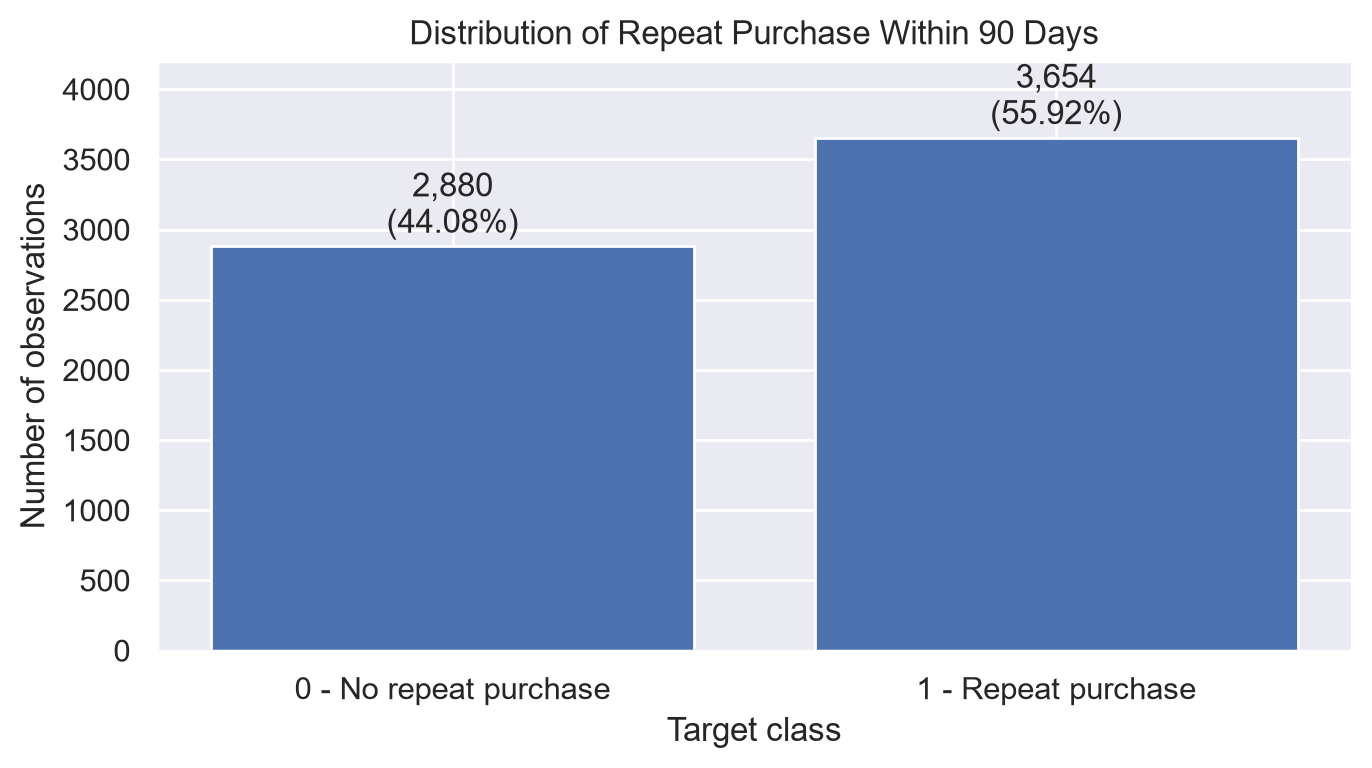

In [23]:
# Target variable exploration

target = "repeat_purchase_90d"

# Count observations in each class
target_counts = bd[target].value_counts().reindex([0, 1], fill_value=0)

# Calculate percentages
target_percentages = (
    target_counts / bd[target].notna().sum() * 100
).round(2)

# Create summary table
target_summary = pd.DataFrame({
    "Number of observations": target_counts,
    "Percentage (%)": target_percentages
})

target_summary.index.name = target

display(target_summary)

# Visualize the target distribution

fig, ax = plt.subplots(figsize=(7, 4))

labels = [
    "0 - No repeat purchase",
    "1 - Repeat purchase"
]

bars = ax.bar(labels, target_counts.values)

# Display counts and percentages
for i, bar in enumerate(bars):
    class_value = target_counts.index[i]
    percentage = target_percentages.loc[class_value]

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 30,
        f"{int(bar.get_height()):,}\n({percentage:.2f}%)",
        ha="center",
        va="bottom"
    )

ax.set_title("Distribution of Repeat Purchase Within 90 Days")
ax.set_xlabel("Target class")
ax.set_ylabel("Number of observations")
ax.set_ylim(0, target_counts.max() * 1.15)

plt.tight_layout()
plt.show()

The target variable, repeat_purchase_90d, indicates whether a customer makes another purchase within 90 days of the observed purchase occasion. It is a binary variable, where 1 represents a repeat purchase within 90 days and 0 represents no repeat purchase within this period.

On this dataset, 3,654 (55.92%) belong to class 1, while 2,880 (44.08%) belong to class 0. Therefore, repeat purchases within 90 days are slightly more frequent than non-repeat purchases.

The distribution is relatively balanced, as neither class overwhelmingly dominates the dataset. Based on this initial analysis, there is no clear indication of a severe class imbalance that would immediately require resampling techniques.

## 5. **Data quality** 

### 5.1. **Missing values**

In [32]:
# Missing values | count and percentage per column
missing_summary = pd.DataFrame({
    "Missing values": bd.isna().sum(),
    "Missing (%)": (bd.isna().mean() * 100).round(2)
})
missing_summary = missing_summary[
    missing_summary["Missing values"] > 0
].sort_values("Missing values", ascending=False)

display(missing_summary)

# Overall missing-value summary
rows_with_missing = bd.isna().any(axis=1).sum()
columns_with_missing = (bd.isna().sum() > 0).sum()
total_missing = bd.isna().sum().sum()

print(f"Total observations: {len(bd)}")
print(f"Rows with missing values: {rows_with_missing}")
print(f"Columns with missing values: {columns_with_missing}")
print(f"Total missing cells: {total_missing}")
print(f"Percentage of rows with missing values: "
      f"{rows_with_missing / len(bd) * 100:.2f}%")

,Missing values,Missing (%)
prior_std_gap_days,1478,22.62
prior_mean_gap_days,1308,20.02
prior_std_purchase_value,1113,17.03
prior_mean_purchase_value,862,13.19
days_since_previous_purchase,861,13.18
prior_max_purchase_value,668,10.22
prior_min_purchase_value,668,10.22
transport_method,261,3.99
warehouse,260,3.98
payment_type,260,3.98


Total observations: 6534
Rows with missing values: 2605
Columns with missing values: 36
Total missing cells: 9818
Percentage of rows with missing values: 39.87%


The data quality analysis identified several issues that require further investigation before preprocessing.

The dataset contains 9,818 missing cells across 36 of its 38 columns. In total, 2,605 observations (39.87%) have at least one missing value. A particularly important finding is that 65 observations contain 36 missing values, with only the target variable and customer_id available. These records may represent incomplete purchase observations and should be investigated before deciding how to handle them.



DIZER O QUE FAZER COM ESTES MISSING VALUES

In [33]:
# Analyse the distribution of missing values across observations

feature_columns = [
    col for col in bd.columns
    if col not in ["customer_id", "repeat_purchase_90d"]
]

missing_per_row = bd[feature_columns].isna().sum(axis=1)

print("Distribution of missing values per row:")
display(
    missing_per_row.value_counts()
    .sort_index()
    .rename_axis("Number of missing features")
    .to_frame("Number of observations")
)

print(
    "\nRows with all feature values missing:",
    (missing_per_row == len(feature_columns)).sum()
)

print(
    "Rows with at least 50% of features missing:",
    (missing_per_row >= len(feature_columns) / 2).sum()
)

Distribution of missing values per row:


,Number of observations
Number of missing features,
0,3929
1,1287
2,190
3,354
4,100
5,6
7,511
8,86
9,6



Rows with all feature values missing: 65
Rows with at least 50% of features missing: 65


In [39]:

# Identify observations with all feature values missing

all_features_missing = (
    missing_per_row == len(feature_columns)
)

incomplete_rows = bd.loc[all_features_missing]

print(
    "Observations with all features missing:",
    len(incomplete_rows)
)

display(incomplete_rows.head(10))


Observations with all features missing: 65


,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,...,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,random_noise
ID,,,,,,,,,,,,,,,,,,,,,
10000457,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,755628,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10000560,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,755628,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10000678,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,427118,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10000679,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,508217,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10000870,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,427118,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10000890,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,670446,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10000955,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,248523,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10000980,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,561391,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10000983,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,334782,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [40]:
# Investigate missing historical variables

history_columns = [
    "prior_purchase_count",
    "days_since_previous_purchase",
    "prior_mean_gap_days",
    "prior_std_gap_days",
    "prior_mean_purchase_value",
    "prior_std_purchase_value",
    "prior_min_purchase_value",
    "prior_max_purchase_value",
    "prior_total_spend"
]

history_columns = [
    col for col in history_columns if col in bd.columns
]

# Check the number of previous purchases
display(
    bd["prior_purchase_count"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("Prior purchase count")
    .to_frame("Number of observations")
)

# Compare missingness in history variables across history groups
history_group = pd.Series(
    "Unknown history",
    index=bd.index,
    name="history_group"
)

history_group.loc[bd["prior_purchase_count"].eq(0)] = (
    "No previous purchases"
)

history_group.loc[bd["prior_purchase_count"].gt(0)] = (
    "Previous purchases"
)

missing_history = (
    bd[history_columns]
    .isna()
    .groupby(history_group)
    .mean()
    .mul(100)
    .round(2)
    .T
)

missing_history.columns.name = "Customer history group"

display(missing_history)

,Number of observations
Prior purchase count,
0.0,603
1.0,445
2.0,365
3.0,319
4.0,270
...,...
273.0,1
274.0,1
275.0,1


Customer history group,No previous purchases,Previous purchases,Unknown history
prior_purchase_count,0.0,0.00,100.0
days_since_previous_purchase,100.0,3.29,100.0
prior_mean_gap_days,100.0,10.91,100.0
prior_std_gap_days,100.0,13.81,100.0
prior_mean_purchase_value,100.0,3.31,100.0
prior_std_purchase_value,100.0,7.59,100.0
prior_min_purchase_value,100.0,0.00,100.0
prior_max_purchase_value,100.0,0.00,100.0
prior_total_spend,0.0,0.00,100.0


In [38]:

# Inspect customer IDs and target values in incomplete rows

display(
    incomplete_rows[
        ["customer_id", "repeat_purchase_90d"]
    ].head(20)
)

print(
    "Unique customers in incomplete rows:",
    incomplete_rows["customer_id"].nunique()
)


,customer_id,repeat_purchase_90d
ID,,
10000457,755628,1
10000560,755628,1
10000678,427118,1
10000679,508217,0
10000870,427118,0
10000890,670446,0
10000955,248523,1
10000980,561391,0
10000983,334782,1


Unique customers in incomplete rows: 53


In [42]:

# Investigate missing historical purchase information

history_columns = [
    "prior_purchase_count",
    "days_since_previous_purchase",
    "prior_mean_gap_days",
    "prior_std_gap_days",
    "prior_mean_purchase_value",
    "prior_std_purchase_value",
    "prior_min_purchase_value",
    "prior_max_purchase_value",
    "prior_total_spend"
]

history_columns = [
    col for col in history_columns
    if col in bd.columns
]

# Compare missingness by previous purchase count
if "prior_purchase_count" in bd.columns:

    history_summary = (
        bd.groupby("prior_purchase_count", dropna=False)
        [history_columns]
        .agg(lambda s: s.isna().mean() * 100)
        .round(2)
    )

    display(history_summary)


,prior_purchase_count,days_since_previous_purchase,prior_mean_gap_days,prior_std_gap_days,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_max_purchase_value,prior_total_spend
prior_purchase_count,,,,,,,,,
0.0,0.0,100.00,100.00,100.0,100.00,100.0,100.0,100.0,0.0
1.0,0.0,4.27,100.00,100.0,4.49,100.0,0.0,0.0,0.0
2.0,0.0,5.48,5.75,100.0,3.01,0.0,0.0,0.0,0.0
3.0,0.0,5.64,5.33,0.0,4.39,0.0,0.0,0.0,0.0
4.0,0.0,2.59,2.59,0.0,4.07,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...
273.0,0.0,0.00,0.00,0.0,0.00,0.0,0.0,0.0,0.0
274.0,0.0,0.00,0.00,0.0,0.00,0.0,0.0,0.0,0.0
275.0,0.0,0.00,0.00,0.0,0.00,0.0,0.0,0.0,0.0



The analysis of missing values reveals that missingness is not necessarily caused by a single issue. Different variables show different missingness patterns, suggesting that some missing values may be structural, while others may represent incomplete information.

#### Historical Purchase Variables

A clear pattern was identified in the historical purchase variables. When `prior_purchase_count` is equal to zero, variables such as `days_since_previous_purchase`, `prior_mean_gap_days`, `prior_std_gap_days`, `prior_mean_purchase_value`, and `prior_std_purchase_value` are missing in 100% of observations.

This pattern suggests that these values may be structurally missing because customers without previous purchases do not have sufficient historical information for these statistics to be calculated.

Similar patterns appear for customers with very few previous purchases. For example, `prior_mean_gap_days` and `prior_std_gap_days` are missing in 100% of observations when `prior_purchase_count` is equal to one. In addition, `prior_std_purchase_value` is missing in 100% of observations when the purchase count is two. These patterns may be explained by the mathematical requirements of the corresponding statistics.

However, not all missing values in historical variables can automatically be considered structural. Some variables still contain missing values among customers with previous purchases, and these cases require further investigation.

An additional pattern was identified when `prior_purchase_count` itself is missing: all the historical variables examined are also missing in 100% of these observations. This suggests a group of records with unavailable historical information, although the reason for this pattern is not yet confirmed.

#### Other Variables

Missing values in non-historical variables should be assessed separately. For example, missing transaction categories or other purchase-related information may indicate that the information was not recorded or is unavailable. These values should not automatically be interpreted as zero or replaced with the most frequent value without considering the meaning of each variable.

#### Missingness Mechanism

The observed patterns suggest that some missing values may be related to the availability of historical purchase information. However, the current analysis is not sufficient to classify the missingness mechanism of the entire dataset as Missing Completely at Random (MCAR), Missing at Random (MAR), or Missing Not at Random (MNAR).

Further investigation is therefore required before selecting an imputation or exclusion strategy.


In [45]:
# Examine the distribution of previous purchase counts

purchase_count_summary = (
    bd["prior_purchase_count"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("Prior purchase count")
    .to_frame("Number of observations")
)

purchase_count_summary["Percentage"] = (
    purchase_count_summary["Number of observations"]
    / len(bd) * 100
).round(2)

display(purchase_count_summary)

print("")
# Count missing feature values for each observation
feature_columns = [
    col for col in bd.columns
    if col not in ["customer_id", "repeat_purchase_90d"]
]
missing_per_row = bd[feature_columns].isna().sum(axis=1)

print("Observations with all features missing:",
      (missing_per_row == len(feature_columns)).sum())

print("Observations with more than half of features missing:",
      (missing_per_row > len(feature_columns) / 2).sum())

,Number of observations,Percentage
Prior purchase count,,
0.0,603,9.23
1.0,445,6.81
2.0,365,5.59
3.0,319,4.88
4.0,270,4.13
...,...,...
273.0,1,0.02
274.0,1,0.02
275.0,1,0.02



Observations with all features missing: 65
Observations with more than half of features missing: 65


**Check 1 —** Do the missing historical values correspond to zero purchases or incomplete records?

**Check 2 —** Are there any records without any information across the features?

 **Observations with Completely Missing Features**

The analysis identified 65 observations (0.99% of the dataset) with all feature variables missing. These observations also have a missing value in prior_purchase_count, and they represent the same 65 records identified in the previous analysis.

This pattern suggests that these records lack historical purchase information and all other available predictor variables. However, the underlying reason for the missingness cannot be determined from the current analysis alone.

Since these observations contain no available features for prediction, they may not be suitable for model training. Therefore, they will be investigated separately, and their exclusion from the training dataset will be considered during preprocessing if the missing information cannot be recovered.



### 5.2. **Duplicate observations and identifiers**

In [ ]:
VER NEGATIVOS

In [38]:
variaveis_com_negativos = [
    coluna for coluna in numericas
    if (bd[coluna] < 0).any()
]
for coluna in variaveis_com_negativos:
    print(coluna, (bd[coluna] < 0).sum())


days_since_previous_purchase 16
prior_mean_purchase_value 16
prior_mean_gap_days 16
spend_365d 15
random_noise 3357


In [ ]:
VER AS LINHAS EM QUE 'days_since_previous_purchase', 'prior_mean_purchase_value', 'prior_mean_gap_days', 'spend_365d', 'random_noise'
TEM VALORES NEGATIVOS, MAS VAMOS IGNORAR O RANDOM_NOISE POR AGORA